# LSTM Classification

### Authors - Shivendra Raghav (1001123853), Amirhosein Morteza (1002187551)
### CSE 5388-002

#### This file implements the LSTM model for document classification.

### Import the required libraries

In [137]:
import os
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, accuracy_score, precision_score, f1_score

### Loading the data



In [138]:
# Read the processed dataset
data = pd.read_csv("../synthetic_dataset/sentence_classified_data_resampled.csv")

# Split the string based on space
data["processed_sentence"] = data["processed_sentence"].astype("str").apply(lambda x: x.split())

# Load Tokenizers
with open("output/text_tokenizer.pickle", "rb") as file:
    tokenizer = pickle.load(file)

# Load GloVe word embeddings for the docs
with np.load("output/glove_embeddings.npz", allow_pickle=True) as glove_embeddings_data:
    glove_embeddings = glove_embeddings_data["embedding_matrix"]

glove_embeddings.shape

(15091, 300)

In [139]:
# Convert the tokens to sequences
sequences = tokenizer.texts_to_sequences(data["processed_sentence"])

# Padding the sequences
text_max_len = 100

text_padded_sequences = tf.keras.preprocessing.sequence.pad_sequences(sequences, maxlen=text_max_len, padding="post")

### Model Creation

In [140]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(text_padded_sequences, data["sensitive"], test_size=0.2, random_state=42)

# Build the LSTM model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=glove_embeddings.shape[0], output_dim=glove_embeddings.shape[1], weights=[glove_embeddings], input_length=text_max_len, trainable=False),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, dropout=0.2, recurrent_dropout=0.2)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_17"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_17 (Embedding)    (None, 100, 300)          4527300   
                                                                 
 bidirectional_5 (Bidirecti  (None, 128)               186880    
 onal)                                                           
                                                                 
 dense_32 (Dense)            (None, 32)                4128      
                                                                 
 dropout_32 (Dropout)        (None, 32)                0         
                                                                 
 dense_33 (Dense)            (None, 1)                 33        
                                                                 
Total params: 4718341 (18.00 MB)
Trainable params: 191041 (746.25 KB)
Non-trainable params: 4527300 (17.27 MB)
________

### Training and Evaluation



In [141]:
model.compile(optimizer="Adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
27/27 [==============================] - 25s 695ms/step - loss: 0.6735 - accuracy: 0.6009 - val_loss: 0.6284 - val_accuracy: 0.6911
Epoch 2/5
27/27 [==============================] - 16s 590ms/step - loss: 0.5567 - accuracy: 0.7301 - val_loss: 0.4835 - val_accuracy: 0.7801
Epoch 3/5
27/27 [==============================] - 16s 600ms/step - loss: 0.4321 - accuracy: 0.8197 - val_loss: 0.4213 - val_accuracy: 0.8115
Epoch 4/5
27/27 [==============================] - 16s 581ms/step - loss: 0.4034 - accuracy: 0.8342 - val_loss: 0.4014 - val_accuracy: 0.8272
Epoch 5/5
27/27 [==============================] - 18s 650ms/step - loss: 0.3573 - accuracy: 0.8546 - val_loss: 0.4031 - val_accuracy: 0.8168


In [142]:
y_pred = model.predict(X_test)
y_pred = (y_pred > 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)

df_scores = pd.DataFrame(columns=["Metric", "Value"])
df_scores = df_scores._append({"Metric": "Accuracy", "Value":accuracy}, ignore_index=True)
df_scores = df_scores._append({"Metric": "Precision", "Value":precision}, ignore_index=True)
df_scores = df_scores._append({"Metric": "Recall", "Value":recall}, ignore_index=True)
df_scores = df_scores._append({"Metric": "F1 score:", "Value":f1}, ignore_index=True)

df_scores.head()

15/15 [==============================] - 1s 67ms/step


,Metric,Value
0,Accuracy,0.815900
1,Precision,0.809339
2,Recall,0.842105
3,F1 score:,0.825397


### Plotting the accuracy

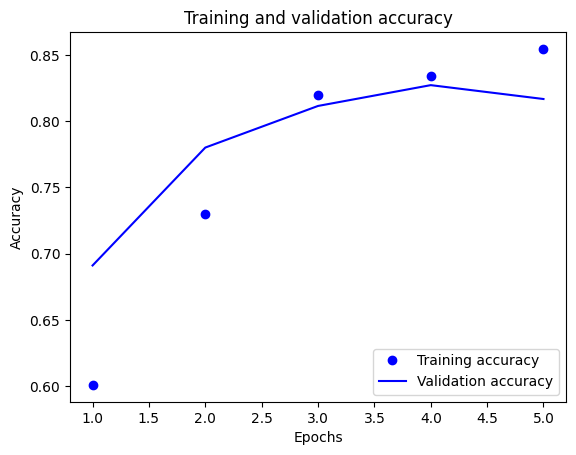

In [143]:
# Plotting the accuracy
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, "bo", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.show()